# Query-Free Adversarial Attack against Stable Diffusion

An independent research implementation of **Zhuang, Zhang and Liu (2023)**,
[A Pilot Study of Query-Free Adversarial Attack against Stable Diffusion](https://arxiv.org/abs/2303.16378).
[Authors' reference implementation](https://github.com/OPTML-Group/QF-Attack).

**Run:** upload this `.ipynb` at [Google Colab](https://colab.research.google.com/), select
**Runtime > Change runtime type > T4 GPU**, and set **Runtime Version to 2026.07**
(Python 3.12), then run the cells in order. The pinned installation targets Python 3.12.
[Google's runtime-version instructions](https://research.google.com/colaboratory/runtime-version-faq.html).
Model weights require several GB of disk space. This notebook is self-contained;
you do not need to upload `qf_attack.py` or the PDF. Keep a fresh runtime for package installation.
If Colab requests a restart after installation, restart and continue from cell 2.

The default experiment attacks two benign scenes using a five-character suffix
(plus a separating space). Search uses only the local CLIP text encoder. Diffusion
is called **after search**, with identical initial noise across clean/attacked conditions.
The model's default safety checker remains enabled; filtered outputs are logged and excluded in pairs.

**Scope:** equations (1)-(2), genetic and coordinate-greedy search, one-sample random,
a genetic-budget-matched random control, and a gradient-based PGD baseline
(encoder-only; no images are generated for its suffixes). The fixed
contexts, operator choices and extended dataset are declared deviations from the paper.
The saved outputs are actual run measurements, never copies of the paper's scores.


In [1]:
# 1. Install known versions before importing the model libraries.
import importlib.util, subprocess, sys
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    if sys.version_info[:2] != (3, 12):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime Version 2026.07 (Python 3.12), then rerun.")
    packages = ['torch==2.6.0', 'torchvision==0.21.0', 'torchaudio==2.6.0', 'transformers==4.49.0', 'diffusers==0.32.2', 'accelerate==1.4.0', 'huggingface-hub==0.28.1', 'safetensors==0.5.3', 'numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0']
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
else:
    print("Local execution: use requirements-colab.txt; installation cell skipped.")


Local execution: use requirements-colab.txt; installation cell skipped.


## Objective and targeted mask

For the complete CLIP final hidden-state tensor $H(x)\in\mathbb{R}^{77\times768}$,
the untargeted objective is $\min_s\cos(\mathrm{vec}H(x),\mathrm{vec}H(x+\text{space}+s))$.
The suffix $s$ contains exactly five characters from the reference alphabet.

For ten fixed context pairs, define $d_i=H(c_i+\text{and}+t)-H(c_i)$ and
$I_j=\mathbf{1}\{|\sum_i\mathrm{sign}(d_{ij})|>0.9n\}$.
The targeted objective minimizes cosine after multiplying **both** tensors by $I$.
With $n=10$, the strict threshold requires unanimous signs. An empty mask raises
an error instead of changing the threshold. Token states are flattened including
EOS padding, matching the authors' implementation. Image evaluation later uses
CLIP's projected, normalized pooled vectors, a different representation.

This objective does not enforce background preservation or even a direction of
concept removal. Evaluate target and retained concepts separately and inspect images.


In [2]:
# 2. Write the standalone implementation (no GitHub clone required).
from pathlib import Path
Path('qf_attack.py').write_text('"""QF-Attack research reimplementation; also embedded in the Colab notebook.\n\nPaper: https://arxiv.org/abs/2303.16378 (Zhuang et al., 2023).\nIndependent implementation of equations (1)-(2), not the authors\' code.\n"""\nfrom __future__ import annotations\n\nimport csv\nimport gc\nimport hashlib\nimport importlib.metadata\nimport json\nimport os\nimport platform\nimport random\nimport time\nfrom dataclasses import asdict, dataclass\nfrom pathlib import Path\n\nos.environ.setdefault("HF_HOME", str(Path.cwd() / ".hf-cache"))\nos.environ.setdefault("TOKENIZERS_PARALLELISM", "false")\n\nimport numpy as np\nimport torch\nimport torch.nn.functional as F\nfrom huggingface_hub import HfApi\nfrom transformers import CLIPTextModel, CLIPTokenizer\n\nSD_ID = "CompVis/stable-diffusion-v1-4"\nCLIP_ID = "openai/clip-vit-large-patch14"\n# Same character set as the reference code, with its duplicate \'*\' removed.\nALPHABET = tuple(dict.fromkeys(list("·~!@#$%^&*()=-*+.<>?,\';:|\\\\/")\n                               + list("ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789")))\nCONTEXTS = [\n    "A bird flying above a river", "A boat floating on a lake",\n    "A teapot resting on a table", "A train crossing the countryside",\n    "A butterfly sitting on a flower", "A lantern glowing beside a window",\n    "A cabin standing beside a forest", "A cloud drifting above a mountain",\n    "A fountain flowing in a garden", "A bridge stretching across a stream",\n]\n# First eight scene prompts are transcribed from the paper\'s figures. Remaining\n# twelve are declared additions, not a recovered copy of the authors\' dataset.\nCASES = [\n    ("A black bicycle against a brick wall", "a black bicycle", "a brick wall"),\n    ("A red apple on a plate", "a plate", "a red apple"),\n    ("A white swan on a lake", "a lake", "a white swan"),\n    ("A purple and blue butterfly on a leaf", "a leaf", "a butterfly"),\n    ("A yellow and black bumblebee on a flower", "a flower", "a bumblebee"),\n    ("A red and white picnic blanket with a basket", "a basket", "a picnic blanket"),\n    ("A yellow sunflower in a field", "a field", "a yellow sunflower"),\n    ("A white snowflake on a blue background", "a white snowflake", "a blue background"),\n    ("A brown dog beside a wooden fence", "a wooden fence", "a brown dog"),\n    ("A blue teapot on a kitchen table", "a blue teapot", "a kitchen table"),\n    ("A white boat beside a lighthouse", "a lighthouse", "a white boat"),\n    ("A green frog on a lily pad", "a lily pad", "a green frog"),\n    ("A red train crossing a stone bridge", "a stone bridge", "a red train"),\n    ("A yellow duck beside a pond", "a pond", "a yellow duck"),\n    ("A glass vase containing pink flowers", "a glass vase", "pink flowers"),\n    ("A black cat sitting on a sofa", "a sofa", "a black cat"),\n    ("A silver car beside a red barn", "a red barn", "a silver car"),\n    ("A white mug beside an open book", "an open book", "a white mug"),\n    ("A sailboat below a cloudy sky", "a sailboat", "a cloudy sky"),\n    ("A brown horse beside a green tree", "a green tree", "a brown horse"),\n]\n\n\n@dataclass\nclass Config:\n    profile: str = "demo"\n    seed: int = 2026\n    suffix_length: int = 5\n    generations: int = 10\n    population: int = 20\n    mutation_probability: float = 0.3\n    greedy_passes: int = 1\n    mask_threshold: float = 0.9\n    batch_size: int = 8\n    n_prompts: int = 2\n    image_seeds: tuple = (27,)\n    steps: int = 20\n    guidance_scale: float = 7.5\n    height: int = 512\n    width: int = 512\n    run_images: bool = True\n    output_dir: str = "qf_results"\n    device: str = "auto"\n    sd_revision: str | None = None\n    clip_revision: str | None = None\n\n    @classmethod\n    def full(cls, **kwargs):\n        return cls(**dict(dict(profile="extended", generations=50, n_prompts=20,\n                              image_seeds=tuple(range(27, 37)), steps=50), **kwargs))\n\n\ndef choose_device(requested="auto"):\n    if requested != "auto":\n        return torch.device(requested)\n    if torch.cuda.is_available():\n        return torch.device("cuda")\n    if torch.backends.mps.is_available():\n        return torch.device("mps")\n    return torch.device("cpu")\n\n\ndef resolve_revision(model_id, revision):\n    # Record immutable commits; pass the saved value to repeat the same weights.\n    if revision and len(revision) == 40:\n        return revision\n    return HfApi().model_info(model_id, revision=revision or "main").sha\n\n\ndef save_json(path, data):\n    Path(path).write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")\n\n\ndef save_csv(path, rows):\n    if not rows:\n        return\n    with open(path, "w", newline="", encoding="utf-8") as f:\n        writer = csv.DictWriter(f, fieldnames=list(rows[0]))\n        writer.writeheader()\n        writer.writerows(rows)\n\n\ndef derive_mask(with_concept, without_concept, threshold=0.9):\n    if with_concept.shape != without_concept.shape or with_concept.ndim != 3:\n        raise ValueError("Expected matching [contexts, 77, hidden] tensors")\n    if not 0 <= threshold < 1:\n        raise ValueError("Mask threshold must lie in [0, 1)")\n    votes = torch.sign(with_concept - without_concept).sum(dim=0)\n    mask = votes.abs() > threshold * with_concept.shape[0]\n    if not mask.any():\n        raise ValueError("Empty concept mask. Change contexts; do not silently relax epsilon.")\n    return mask.flatten().float()\n\n\nclass TextOracle:\n    """Flatten all 77 final hidden states, including EOS padding, as reference code does.\n\n    This is NOT the normalized, projected pooled vector used for image CLIP scores.\n    """\n    def __init__(self, cfg):\n        self.device = choose_device(cfg.device)\n        self.batch_size = cfg.batch_size\n        self.tokenizer = CLIPTokenizer.from_pretrained(\n            SD_ID, subfolder="tokenizer", revision=cfg.sd_revision)\n        self.model = CLIPTextModel.from_pretrained(\n            SD_ID, subfolder="text_encoder", revision=cfg.sd_revision,\n            torch_dtype=torch.float32, use_safetensors=True).eval().to(self.device)\n        self.model.requires_grad_(False)\n        self.texts_encoded = 0\n        self.forward_batches = 0\n\n    def validate(self, texts):\n        lengths = [len(ids) for ids in self.tokenizer(texts, truncation=False)["input_ids"]]\n        if max(lengths) > self.tokenizer.model_max_length:\n            raise ValueError("Prompt exceeds CLIP context; refusing silent truncation")\n\n    @torch.inference_mode()\n    def encode(self, texts):\n        self.validate(texts)\n        parts = []\n        for start in range(0, len(texts), self.batch_size):\n            batch = texts[start:start + self.batch_size]\n            tokens = self.tokenizer(batch, padding="max_length", truncation=False,\n                                    max_length=self.tokenizer.model_max_length,\n                                    return_tensors="pt")\n            # No padding attention mask, matching the SD v1.x conditioning path.\n            h = self.model(input_ids=tokens.input_ids.to(self.device)).last_hidden_state\n            parts.append(h.float().cpu())\n            self.texts_encoded += len(batch)\n            self.forward_batches += 1\n        return torch.cat(parts)\n\n    def concept_mask(self, concept, threshold):\n        with_concept = self.encode([s + " and " + concept for s in CONTEXTS])\n        without = self.encode(CONTEXTS)\n        return derive_mask(with_concept, without, threshold)\n\n\nclass Objective:\n    def __init__(self, oracle, prompt, mask=None, length=5):\n        self.oracle, self.prompt, self.length = oracle, prompt, length\n        # Reserve enough tokens for worst-case suffix segmentation and a separator.\n        if len(oracle.tokenizer(prompt)["input_ids"]) + 2 * length + 2 > 77:\n            raise ValueError("Base prompt too long for a five-character attack")\n        self.reference = oracle.encode([prompt]).flatten()\n        self.mask = torch.ones_like(self.reference) if mask is None else mask\n        if self.mask.shape != self.reference.shape or not self.mask.any():\n            raise ValueError("Invalid mask")\n        self.unit_reference = F.normalize(self.reference * self.mask, dim=0)\n        self.cache = {}\n        self.history = []\n        self.requests = 0\n\n    def score(self, suffixes):\n        self.requests += len(suffixes)\n        for suffix in suffixes:\n            if len(suffix) != self.length or any(c not in ALPHABET for c in suffix):\n                raise ValueError("Suffix violates the character constraint")\n        missing = list(dict.fromkeys(s for s in suffixes if s not in self.cache))\n        for start in range(0, len(missing), self.oracle.batch_size):\n            part = missing[start:start + self.oracle.batch_size]\n            h = self.oracle.encode([self.prompt + " " + s for s in part]).flatten(1)\n            vals = F.normalize(h * self.mask, dim=1) @ self.unit_reference\n            self.cache.update(zip(part, vals.tolist()))\n        return [self.cache[s] for s in suffixes]\n\n    def log(self, iteration):\n        suffix = min(self.cache, key=self.cache.get)\n        self.history.append(dict(iteration=iteration, best_loss=self.cache[suffix],\n                                 unique_candidates=len(self.cache), suffix=suffix))\n\n    def best(self):\n        return min(self.cache, key=self.cache.get)\n\n\ndef random_suffix(rng, length):\n    return "".join(rng.choices(ALPHABET, k=length))\n\n\ndef single_random(obj, rng, cfg):\n    obj.score([random_suffix(rng, cfg.suffix_length)])\n    obj.log(0)\n    return obj.best()\n\n\ndef greedy(obj, rng, cfg):\n    current = random_suffix(rng, cfg.suffix_length)\n    obj.score([current])\n    obj.log(0)\n    for sweep in range(cfg.greedy_passes):\n        for pos in range(cfg.suffix_length):\n            candidates = [current[:pos] + c + current[pos + 1:] for c in ALPHABET]\n            vals = obj.score(candidates)\n            current = candidates[int(np.argmin(vals))]\n            obj.log(sweep * cfg.suffix_length + pos + 1)\n    return obj.best()\n\n\ndef genetic(obj, rng, cfg):\n    if cfg.population < 4 or cfg.suffix_length < 2:\n        raise ValueError("GA requires population >=4 and suffix length >=2")\n    population = [random_suffix(rng, cfg.suffix_length) for _ in range(cfg.population)]\n    for generation in range(cfg.generations + 1):\n        scores = obj.score(population)\n        ranked = sorted(zip(scores, population))\n        obj.log(generation)\n        if generation == cfg.generations:\n            break\n        # Explicit implementation choices: two elites, three-way tournaments,\n        # one-point crossover, and one mutated character with probability 0.3.\n        def parent():\n            return min(rng.sample(ranked, 3))[1]\n        next_population = [item[1] for item in ranked[:2]]\n        while len(next_population) < cfg.population:\n            a, b = parent(), parent()\n            cut = rng.randrange(1, cfg.suffix_length)\n            child = a[:cut] + b[cut:]\n            if rng.random() < cfg.mutation_probability:\n                pos = rng.randrange(cfg.suffix_length)\n                child = child[:pos] + rng.choice(ALPHABET) + child[pos + 1:]\n            next_population.append(child)\n        population = next_population\n    return obj.best()\n\n\ndef budget_random(obj, rng, cfg, budget):\n    # Same number of unique candidate encoder evaluations as this prompt\'s GA.\n    while len(obj.cache) < budget:\n        n = min(cfg.batch_size, budget - len(obj.cache))\n        candidates = []\n        while len(candidates) < n:\n            s = random_suffix(rng, cfg.suffix_length)\n            if s not in obj.cache and s not in candidates:\n                candidates.append(s)\n        obj.score(candidates)\n        obj.log(len(obj.cache))\n    return obj.best()\n\n\ndef run_search(cfg):\n    out = Path(cfg.output_dir)\n    out.mkdir(parents=True, exist_ok=True)\n    if not 1 <= cfg.n_prompts <= len(CASES):\n        raise ValueError("n_prompts outside the available dataset")\n    cfg.sd_revision = resolve_revision(SD_ID, cfg.sd_revision)\n    torch.manual_seed(cfg.seed)\n    if torch.cuda.is_available():\n        torch.backends.cuda.matmul.allow_tf32 = False\n    oracle = TextOracle(cfg)\n    started = time.perf_counter()\n    rows, traces, mask_stats = [], {}, []\n    for case_id, (prompt, target, retain) in enumerate(CASES[:cfg.n_prompts]):\n        mask = oracle.concept_mask(target, cfg.mask_threshold)\n        np.save(out / f"mask_{case_id:02d}.npy", mask.numpy())\n        mask_stats.append(dict(case_id=case_id, target=target, selected=int(mask.sum()),\n                               total=mask.numel(), fraction=float(mask.mean())))\n        for mode in ("untargeted", "targeted"):\n            mode_mask = None if mode == "untargeted" else mask\n            ga_budget = None\n            for method_id, method in enumerate(("random", "greedy", "genetic", "budget_random")):\n                obj = Objective(oracle, prompt, mode_mask, cfg.suffix_length)\n                rng_seed = cfg.seed + 1000 * case_id + 100 * (mode == "targeted") + method_id\n                rng = random.Random(rng_seed)\n                before_batches = oracle.forward_batches\n                t = time.perf_counter()\n                if method == "budget_random":\n                    suffix = budget_random(obj, rng, cfg, ga_budget)\n                else:\n                    suffix = {"random": single_random, "greedy": greedy,\n                              "genetic": genetic}[method](obj, rng, cfg)\n                elapsed = time.perf_counter() - t\n                search_batches = oracle.forward_batches - before_batches\n                if method == "genetic":\n                    ga_budget = len(obj.cache)\n                h = oracle.encode([prompt + " " + suffix]).flatten()\n                full_cosine = float(F.cosine_similarity(obj.reference, h, dim=0))\n                masked_cosine = float(F.cosine_similarity(obj.reference * mask, h * mask, dim=0))\n                row = dict(case_id=case_id, prompt=prompt, target=target, retain=retain,\n                           mode=mode, method=method, suffix=suffix, attacked_prompt=prompt + " " + suffix,\n                           objective_cosine=obj.cache[suffix], full_cosine=full_cosine,\n                           masked_cosine=masked_cosine, candidate_requests=obj.requests,\n                           unique_candidates=len(obj.cache), forward_batches=search_batches,\n                           diffusion_queries_during_search=0, rng_seed=rng_seed,\n                           search_seconds=elapsed)\n                rows.append(row)\n                traces[f"{case_id}_{mode}_{method}"] = dict(history=obj.history,\n                                                            candidate_scores=obj.cache)\n                print(f"{case_id} {mode:10s} {method:13s} {suffix!r} "\n                      f"loss={obj.cache[suffix]:.5f} candidates={len(obj.cache)}", flush=True)\n                save_csv(out / "attack_results.csv", rows)\n    save_json(out / "search_traces.json", traces)\n    save_json(out / "mask_statistics.json", mask_stats)\n    versions = {p: importlib.metadata.version(p) for p in\n                ("torch", "transformers", "diffusers", "accelerate", "huggingface-hub", "numpy")}\n    manifest = dict(config=asdict(cfg), device=str(oracle.device), platform=platform.platform(),\n                    python=platform.python_version(), versions=versions,\n                    text_encoder_shape=list(oracle.encode([CASES[0][0]]).shape),\n                    total_texts_encoded=oracle.texts_encoded,\n                    total_forward_batches=oracle.forward_batches,\n                    elapsed_seconds=time.perf_counter() - started,\n                    diffusion_queries_during_search=0, images_evaluated=False,\n                    alphabet="".join(ALPHABET), contexts=CONTEXTS,\n                    cases=CASES[:cfg.n_prompts],\n                    source_sha256=hashlib.sha256(Path(__file__).read_bytes()).hexdigest())\n    save_json(out / "manifest.json", manifest)\n    del oracle\n    gc.collect()\n    if torch.cuda.is_available():\n        torch.cuda.empty_cache()\n    if torch.backends.mps.is_available():\n        torch.mps.empty_cache()\n    return rows\n\n\ndef generate_images(cfg, attack_rows):\n    """Post-search only. Every condition uses the exact same saved initial latent."""\n    from diffusers import StableDiffusionPipeline\n    from PIL import Image, ImageDraw\n    device = choose_device(cfg.device)\n    if device.type == "cpu":\n        raise RuntimeError("Image generation needs a GPU. Set run_images=False for text-only mode.")\n    out = Path(cfg.output_dir)\n    (out / "images").mkdir(exist_ok=True)\n    dtype = torch.float16\n    settings = dict(model=SD_ID, revision=cfg.sd_revision, steps=cfg.steps,\n                    guidance_scale=cfg.guidance_scale, height=cfg.height, width=cfg.width,\n                    image_seeds=list(cfg.image_seeds), cases=[list(c) for c in CASES[:cfg.n_prompts]],\n                    dtype=str(dtype), device=str(device), attention="default SDPA",\n                    versions={p: importlib.metadata.version(p) for p in ("torch", "diffusers", "transformers")},\n                    conditions=[dict(case_id=int(r["case_id"]), mode=r["mode"],\n                                     method=r["method"], attacked_prompt=r["attacked_prompt"])\n                                for r in attack_rows])\n    settings_path = out / "generation_settings.json"\n    source_sha = hashlib.sha256(Path(__file__).read_bytes()).hexdigest()\n    cached = {}\n    if settings_path.exists():\n        previous = json.loads(settings_path.read_text())\n        if previous["settings"] != settings:\n            raise ValueError("Existing image settings differ. Use a new output directory.")\n        if (out / "image_manifest.csv").exists():\n            for r in csv.DictReader((out / "image_manifest.csv").open()):\n                r["filtered"] = {"True": True, "False": False, "": None}[r["filtered"]]\n                r["image_source_sha256"] = r.get("image_source_sha256") or previous["initial_source_sha256"]\n                cached[(int(r["case_id"]), int(r["seed"]), r["mode"], r["method"])] = r\n    else:\n        if (out / "image_manifest.csv").exists():\n            raise ValueError("Existing images lack generation settings. Use a new output directory.")\n        save_json(settings_path, dict(settings=settings, initial_source_sha256=source_sha))\n    (out / "generation_sources").mkdir(exist_ok=True)\n    (out / "generation_sources" / (source_sha + ".py")).write_bytes(Path(__file__).read_bytes())\n    pipe = StableDiffusionPipeline.from_pretrained(\n        SD_ID, revision=cfg.sd_revision, variant="fp16", torch_dtype=dtype,\n        use_safetensors=True)\n    # PyTorch 2 uses memory-efficient SDPA. Attention slicing replaces that\n    # processor and can severely slow inference; leave SDPA enabled.\n    pipe.enable_vae_slicing()\n    if device.type == "cuda":\n        pipe.enable_model_cpu_offload()\n    else:\n        pipe.to(device)\n    pipe.set_progress_bar_config(disable=True)\n    save_json(out / "scheduler.json", dict(pipe.scheduler.config))\n    manifest = json.loads((out / "manifest.json").read_text())\n    manifest.update(generation_device=str(device), generation_dtype=str(dtype),\n                    generation_weight_variant="fp16", attention_backend="default SDPA")\n    save_json(out / "manifest.json", manifest)\n    image_rows = []\n    for case_id, (prompt, target, retain) in enumerate(CASES[:cfg.n_prompts]):\n        conditions = [dict(mode="clean", method="clean", suffix="", attacked_prompt=prompt)]\n        conditions += [r for r in attack_rows if r["case_id"] == case_id]\n        for seed in cfg.image_seeds:\n            # Draw once on CPU; clone it for every condition (including clean).\n            latent = torch.randn((1, pipe.unet.config.in_channels, cfg.height // 8, cfg.width // 8),\n                                 generator=torch.Generator("cpu").manual_seed(seed), dtype=torch.float32)\n            latent_hash = hashlib.sha256(latent.numpy().tobytes()).hexdigest()\n            tiles = []\n            for row in conditions:\n                stem = f"{case_id:02d}_{seed}_{row[\'mode\']}_{row[\'method\']}"\n                path = out / "images" / f"{stem}.png"\n                old = cached.get((case_id, seed, row["mode"], row["method"]))\n                reused = old is not None and path.exists()\n                if reused:\n                    if old["suffix"] != row["suffix"] or old["latent_sha256"] != latent_hash:\n                        raise ValueError("Cached image does not match suffix and initial noise")\n                    picture = Image.open(path).convert("RGB")\n                    if picture.size != (cfg.width, cfg.height):\n                        raise ValueError("Cached image dimensions differ")\n                    filtered = old["filtered"]\n                    image_source = old["image_source_sha256"]\n                else:\n                    result = pipe(row["attacked_prompt"], latents=latent.clone().to(device, dtype),\n                                  generator=torch.Generator("cpu").manual_seed(seed),\n                                  num_inference_steps=cfg.steps, guidance_scale=cfg.guidance_scale,\n                                  height=cfg.height, width=cfg.width)\n                    picture = result.images[0]\n                    picture.save(path)\n                    flags = result.nsfw_content_detected\n                    filtered = None if flags is None else bool(flags[0])\n                    image_source = source_sha\n                if filtered is not True and np.asarray(picture).max() == 0:\n                    raise RuntimeError("Unfiltered black image: check inference precision/device before scoring")\n                image_rows.append(dict(case_id=case_id, seed=seed, mode=row["mode"],\n                                       method=row["method"], prompt=prompt, target=target,\n                                       retain=retain, suffix=row["suffix"], image_path=str(path),\n                                       filtered=filtered, latent_sha256=latent_hash,\n                                       image_source_sha256=image_source))\n                tile = Image.new("RGB", (256, 288), "white")\n                tile.paste(picture.resize((256, 256)), (0, 32))\n                ImageDraw.Draw(tile).text((5, 5), row["mode"] + "/" + row["method"], fill="black")\n                tiles.append(tile)\n                print("Reused" if reused else "Generated", stem, "filtered:", filtered, flush=True)\n                save_csv(out / "image_manifest.csv", image_rows)\n            grid = Image.new("RGB", (3 * 256, 3 * 288), "#eeeeee")\n            for i, tile in enumerate(tiles):\n                grid.paste(tile, ((i % 3) * 256, (i // 3) * 288))\n            grid.save(out / f"grid_{case_id:02d}_{seed}.png")\n    manifest = json.loads((out / "manifest.json").read_text())\n    manifest["image_generation_sources"] = sorted({r["image_source_sha256"] for r in image_rows})\n    save_json(out / "manifest.json", manifest)\n    del pipe\n    gc.collect()\n    if device.type == "cuda":\n        torch.cuda.empty_cache()\n    if device.type == "mps":\n        torch.mps.empty_cache()\n    return image_rows\n\n\ndef evaluate_images(cfg, image_rows):\n    from PIL import Image\n    from transformers import CLIPModel, CLIPProcessor\n    cfg.clip_revision = resolve_revision(CLIP_ID, cfg.clip_revision)\n    device = choose_device(cfg.device)\n    model = CLIPModel.from_pretrained(CLIP_ID, revision=cfg.clip_revision,\n                                     use_safetensors=True).eval().to(device)\n    processor = CLIPProcessor.from_pretrained(CLIP_ID, revision=cfg.clip_revision)\n    scores = []\n    with torch.inference_mode():\n        for row in image_rows:\n            # Filtered images are explicitly missing, never counted as attack wins.\n            score = dict(row)\n            score.update(full_score=None, target_score=None, retain_score=None)\n            if row["filtered"] is not True:\n                texts = [row["prompt"], "This is a photo of " + row["target"],\n                         "This is a photo of " + row["retain"]]\n                data = processor(text=texts, images=Image.open(row["image_path"]).convert("RGB"),\n                                 padding=True, return_tensors="pt")\n                data = {k: v.to(device) for k, v in data.items()}\n                result = model(**data)\n                # Raw cosine: no 100x multiplier, softmax, clamp, or logit scale.\n                values = (result.text_embeds @ result.image_embeds.T).flatten().tolist()\n                score.update(zip(("full_score", "target_score", "retain_score"), values))\n            scores.append(score)\n    out = Path(cfg.output_dir)\n    save_csv(out / "image_scores.csv", scores)\n    clean = {(r["case_id"], r["seed"]): r for r in scores if r["mode"] == "clean"}\n    paired = []\n    for row in scores:\n        if row["mode"] == "clean":\n            continue\n        base = clean[(row["case_id"], row["seed"])]\n        if row["full_score"] is None or base["full_score"] is None:\n            continue\n        pair = {k: row[k] for k in ("case_id", "seed", "mode", "method")}\n        for metric in ("full", "target", "retain"):\n            # Positive drop means lower text-image alignment after perturbation.\n            pair[metric + "_drop"] = base[metric + "_score"] - row[metric + "_score"]\n        paired.append(pair)\n    save_csv(out / "paired_drops.csv", paired)\n    # Prompt, rather than image, is the resampling unit (seeds are nested).\n    summary = []\n    for mode in ("untargeted", "targeted"):\n        for method in ("random", "greedy", "genetic", "budget_random"):\n            group = [r for r in paired if r["mode"] == mode and r["method"] == method]\n            metric = "full_drop" if mode == "untargeted" else "target_drop"\n            prompt_ids = sorted({r["case_id"] for r in group})\n            means = np.array([np.mean([r[metric] for r in group if r["case_id"] == i])\n                              for i in prompt_ids])\n            lo = hi = None\n            if len(means) >= 5:\n                rng = np.random.default_rng(cfg.seed)\n                boot = rng.choice(means, size=(5000, len(means)), replace=True).mean(1)\n                lo, hi = np.quantile(boot, [.025, .975]).tolist()\n            summary.append(dict(mode=mode, method=method, metric=metric,\n                                prompts=len(means), valid_pairs=len(group),\n                                mean_drop=float(means.mean()) if len(means) else None,\n                                prompt_sd=float(means.std(ddof=1)) if len(means) > 1 else None,\n                                ci95_low=lo, ci95_high=hi,\n                                retain_mean_drop=float(np.mean([r["retain_drop"] for r in group]))\n                                if group else None))\n    save_csv(out / "image_summary.csv", summary)\n    manifest = json.loads((out / "manifest.json").read_text())\n    manifest.update(images_evaluated=True, image_count=len(image_rows),\n                    filtered_count=sum(r["filtered"] is True for r in image_rows),\n                    paired_count=len(paired), clip_revision=cfg.clip_revision,\n                    config=asdict(cfg))\n    save_json(out / "manifest.json", manifest)\n    del model\n    gc.collect()\n    return summary\n\n\ndef write_run_report(cfg):\n    """Generate a factual report from saved results; never insert expected image scores."""\n    out = Path(cfg.output_dir)\n    manifest = json.loads((out / "manifest.json").read_text())\n    rows = list(csv.DictReader((out / "attack_results.csv").open()))\n    lines = ["# QF-Attack: measured run report", "",\n             f"Profile: {cfg.profile}; prompts: {cfg.n_prompts}; device: {manifest[\'device\']}.",\n             "All search losses below are TEXT-TEXT cosine, not image CLIP scores.", "",\n             "| Case | Objective | Method | Suffix | Objective cosine | Unique candidates |",\n             "|---|---|---|---|---:|---:|"]\n    for r in rows:\n        # HTML code avoids Markdown table breakage from adversarial punctuation.\n        import html\n        suffix = html.escape(r["suffix"]).replace("|", "&#124;")\n        lines.append(f"| {r[\'case_id\']} | {r[\'mode\']} | {r[\'method\']} | <code>{suffix}</code> | "\n                     f"{float(r[\'objective_cosine\']):.5f} | {r[\'unique_candidates\']} |")\n    lines += ["", "Diffusion calls during suffix search: 0.",\n              "The five-character suffix excludes the one separating space.",\n              "With 10 contexts and a strict >0.9n vote threshold, all 10 signs must agree.", ""]\n    if manifest["images_evaluated"]:\n        lines += ["## Image evaluation", "",\n                  "Positive drops are clean minus attacked raw CLIP cosine; larger drops indicate reduced alignment.",\n                  "Target removal also requires retained-content inspection; CLIP similarity alone does not prove removal.",\n                  "", "| Objective | Method | Valid pairs | Mean drop | Retained-content drop |",\n                  "|---|---|---:|---:|---:|"]\n        for r in csv.DictReader((out / "image_summary.csv").open()):\n            lines.append(f"| {r[\'mode\']} | {r[\'method\']} | {r[\'valid_pairs\']} | "\n                         f"{r[\'mean_drop\']} | {r[\'retain_mean_drop\']} |")\n        lines += ["", f"Images: {manifest[\'image_count\']}; filtered: {manifest[\'filtered_count\']}.",\n                  "Confidence intervals are omitted below five independent prompts."]\n    else:\n        lines += ["## Image evaluation status", "",\n                  "Image generation and image CLIP evaluation were not executed in this run.",\n                  "These encoder measurements cannot establish image attack success or targeted object removal.",\n                  "Run the image cells on a Colab GPU to populate image_scores.csv and image_summary.csv."]\n    lines += ["", "## Reproduction limits", "",\n              "This implements equations (1)-(2), genetic search, coordinate greedy, single random and budget-matched random.",\n              "PGD is not implemented. Genetic operator details, fixed mask contexts and the extended prompt set differ from the paper.",\n              "This is a method reproduction, not an exact replication of its Table 1.",\n              "", "Sources: [paper](https://arxiv.org/abs/2303.16378); "\n              "[reference code](https://github.com/OPTML-Group/QF-Attack)."]\n    (out / "run_report.md").write_text("\\n".join(lines) + "\\n", encoding="utf-8")\n    return out / "run_report.md"\n\n\nif __name__ == "__main__":\n    import argparse\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--profile", choices=("demo", "extended"), default="demo")\n    parser.add_argument("--text-only", action="store_true")\n    parser.add_argument("--device", default="auto")\n    parser.add_argument("--output", default="qf_results")\n    args = parser.parse_args()\n    factory = Config if args.profile == "demo" else Config.full\n    config = factory(run_images=not args.text_only, device=args.device, output_dir=args.output)\n    attacks = run_search(config)\n    if config.run_images:\n        images = generate_images(config, attacks)\n        evaluate_images(config, images)\n    print(write_run_report(config))\n', encoding='utf-8')
import qf_attack as qf
print('Implementation loaded; alphabet size:', len(qf.ALPHABET))


/Users/smraalam/Downloads/qf-adv/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Implementation loaded; alphabet size: 62


In [3]:
# 3. Experiment settings. The environment override is only for local verification.
import os
PROFILE = "demo"  # @param ["demo", "extended"]
RUN_IMAGES = True  # @param {type:"boolean"}
OUTPUT_DIR = "qf_results"  # @param {type:"string"}
SEED = 2026  # @param {type:"integer"}

factory = qf.Config if PROFILE == "demo" else qf.Config.full
cfg = factory(seed=SEED, run_images=RUN_IMAGES, output_dir=OUTPUT_DIR)
if os.environ.get("QF_TEXT_ONLY") == "1":
    cfg.run_images = False
if os.environ.get("QF_SD_REVISION"):
    cfg.sd_revision = os.environ["QF_SD_REVISION"]
print(cfg)
print("Selected device:", qf.choose_device(cfg.device))
print("Planned images:", cfg.n_prompts * len(cfg.image_seeds) * 9 if cfg.run_images else 0)
# Optional Hugging Face authentication, only if model access requires it:
# from huggingface_hub import notebook_login
# notebook_login()  # use the interactive widget; do not paste tokens in source code


Config(profile='demo', seed=2026, suffix_length=5, generations=10, population=20, mutation_probability=0.3, greedy_passes=1, mask_threshold=0.9, batch_size=8, n_prompts=2, image_seeds=(27,), steps=20, guidance_scale=7.5, height=512, width=512, run_images=False, output_dir='qf_results', device='auto', sd_revision='133a221b8aa7292a167afc5127cb63fb5005638b', clip_revision=None)
Selected device: mps
Planned images: 0


## Search: zero diffusion queries

`demo`: 2 prompts, 10 GA generations, population 20, mutation probability 0.3,
one greedy sweep, one paired image seed and 20 denoising steps (18 images).
`extended`: 20 declared prompts, 50 generations, 50 denoising steps and 10 image
seeds per prompt (1,800 images across 9 conditions). This larger run may exceed
a free Colab session. Neither profile recovers the authors' exact 20-prompt dataset.

The matched random control receives exactly as many **unique candidate** encoder
evaluations as that case's genetic search. Mask construction, clean-reference
encoding and diagnostic rescoring are separately included in total encoder counts.
Searches have independent saved RNG seeds. No diffusion result selects a suffix.


In [4]:
# 4. Run both untargeted and targeted search; checkpoint rows after every method.
attacks = qf.run_search(cfg)
import pandas as pd
attack_df = pd.DataFrame(attacks)
display(attack_df[["case_id", "mode", "method", "suffix", "objective_cosine",
                   "full_cosine", "masked_cosine", "unique_candidates", "search_seconds"]])
assert (attack_df.diffusion_queries_during_search == 0).all()
assert attack_df.suffix.map(len).eq(5).all()


0 untargeted random        '^FF1%' loss=0.86276 candidates=1


0 untargeted greedy        'FC·!U' loss=0.67223 candidates=306


0 untargeted genetic       '|ZPV>' loss=0.69346 candidates=106


0 untargeted budget_random 'E2|,D' loss=0.69014 candidates=106


0 targeted   random        '.7P<Y' loss=0.85095 candidates=1


0 targeted   greedy        'DJE$8' loss=0.60104 candidates=306


... (7 outputs left out)

1 targeted   greedy        'GP38I' loss=0.59528 candidates=306


1 targeted   genetic       'Y!KD8' loss=0.71072 candidates=94


1 targeted   budget_random 'X27QH' loss=0.74572 candidates=94


,case_id,mode,method,suffix,objective_cosine,full_cosine,masked_cosine,unique_candidates,search_seconds
0,0,untargeted,random,^FF1%,0.862755,0.862755,0.852332,1,0.014969
1,0,untargeted,greedy,FC·!U,0.672228,0.672228,0.618948,306,2.607745
2,0,untargeted,genetic,|ZPV>,0.693461,0.693461,0.662844,106,0.979531
3,0,untargeted,budget_random,"E2|,D",0.690142,0.690142,0.654942,106,0.885912
4,0,targeted,random,.7P<Y,0.850952,0.860847,0.850952,1,0.014100
5,0,targeted,greedy,DJE$8,0.601040,0.661550,0.601041,306,2.570942
6,0,targeted,genetic,61PV',0.741119,0.768368,0.741119,105,0.944977
7,0,targeted,budget_random,QMT$9,0.708674,0.754964,0.708674,105,0.858535
8,1,untargeted,random,H3X4\,0.825393,0.825393,0.825288,1,0.013790
9,1,untargeted,greedy,.Y1$),0.723088,0.723088,0.692450,306,2.567387


Matplotlib is building the font cache; this may take a moment.


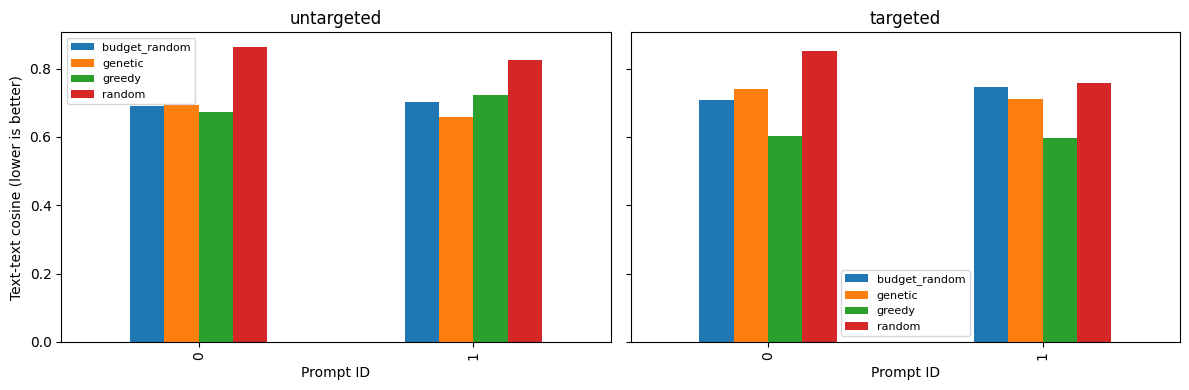

In [5]:
# 5. Plot measured encoder objectives. These are NOT image CLIP scores.
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, mode in zip(axes, ("untargeted", "targeted")):
    part = attack_df[attack_df["mode"] == mode]
    table = part.pivot(index="case_id", columns="method", values="objective_cosine")
    table.plot.bar(ax=ax)
    ax.set(title=mode, xlabel="Prompt ID", ylabel="Text-text cosine (lower is better)")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(Path(cfg.output_dir) / "encoder_objectives.png", dpi=180)
plt.show()


## PGD: gradient-based baseline (encoder-only)

The paper also reports a gradient attack (PGD). Each of the five suffix slots holds
a relaxed distribution over the alphabet; Gumbel-softmax draws near-discrete samples
and a sign-gradient step maximizes $1/\cos$ for 100 iterations. The final discrete
suffix is scored with the same flattened-embedding cosine as the other methods, so
it is directly comparable to the Table above. This is a reproduction of a published
baseline, not a stronger attack. No diffusion model is involved and no images are
generated for PGD suffixes. It runs on the GPU when available, falling back to CPU
on Apple MPS, where Gumbel-softmax is unsupported.


In [6]:
# 5b. PGD (gradient-based) attack on the text embedding. Encoder-only; no images.
import dataclasses
import numpy as np
import torch
import torch.nn.functional as F
from transformers.modeling_attn_mask_utils import _create_4d_causal_attention_mask

PGD_ITERS, PGD_BATCH, PGD_ETA, PGD_SEED = 100, 16, 1.0, SEED
_dev = qf.choose_device(cfg.device)
pgd_device = "cpu" if _dev.type == "mps" else str(_dev)  # Gumbel-softmax unsupported on MPS
pgd_cfg = dataclasses.replace(cfg, device=pgd_device)
pgd_oracle = qf.TextOracle(pgd_cfg)
_tm = pgd_oracle.model.text_model
_A = qf.ALPHABET

def _tok_pos(text):
    ids = pgd_oracle.tokenizer(text, padding="max_length", truncation=True,
                               max_length=77, return_tensors="pt").input_ids.to(pgd_device)
    with torch.no_grad():
        return _tm.embeddings(input_ids=ids)

def _forward(embeds):
    m = _create_4d_causal_attention_mask((1, embeds.shape[1]), embeds.dtype, device=embeds.device)
    out = _tm.encoder(inputs_embeds=embeds, causal_attention_mask=m)[0]
    return _tm.final_layer_norm(out)

def _candidate_embeds():
    rows = [_tok_pos((ch + " ") * 75)[0] for ch in _A]  # [77, dim] per character
    return torch.stack(rows, dim=1)                     # [77, C, dim]

def _run_pgd(prompt, mask, length, iters, batch, eta, seed):
    torch.manual_seed(seed)
    candidate = _candidate_embeds().to(pgd_device)
    orig = _tok_pos(prompt)
    with torch.no_grad():
        clean_out = _forward(orig).flatten()
    mask_vec = mask.to(pgd_device) if mask is not None else torch.ones_like(clean_out)
    clean_ref = F.normalize(clean_out * mask_vec, dim=0)
    num_word = len(prompt.split(" "))
    z = torch.zeros(77, 1, device=pgd_device)
    z[num_word + 1:num_word + length + 1] = 1.0
    u = torch.full((77, len(_A)), 1.0 / len(_A), device=pgd_device, requires_grad=True)
    base = orig[0]
    def embed_from(onehot):
        picked = torch.einsum("pc,pcd->pd", onehot, candidate)
        return ((1 - z) * base + z * picked).unsqueeze(0)
    def masked_cos(out):
        v = F.normalize(out.flatten() * mask_vec, dim=0)
        return torch.dot(v, clean_ref)
    def suffix_of(sample):
        idx = sample[num_word + 1:num_word + length + 1].argmax(dim=1)
        return "".join(_A[i] for i in idx.tolist())
    best_suffix, best_loss = None, -float("inf")
    lr = eta / np.sqrt(iters)
    for _ in range(iters):
        samples = [F.gumbel_softmax(u, tau=0.5, hard=True, dim=-1) for _ in range(batch)]
        losses = [1.0 / masked_cos(_forward(embed_from(s))) for s in samples]
        ranked = sorted(zip(losses, samples), key=lambda x: x[0].item(), reverse=True)
        if ranked[0][0].item() > best_loss:
            best_loss = ranked[0][0].item()
            best_suffix = suffix_of(ranked[0][1].detach())
        total = sum(loss for loss, _ in ranked[:5])
        if u.grad is not None:
            u.grad.zero_()
        total.backward()
        with torch.no_grad():
            u += lr * torch.sign(u.grad)
    return best_suffix

pgd_rows = []
for case_id, (prompt, target, retain) in enumerate(qf.CASES[:cfg.n_prompts]):
    mask = torch.from_numpy(np.load(Path(cfg.output_dir) / f"mask_{case_id:02d}.npy")).float()
    reference = pgd_oracle.encode([prompt]).flatten()
    for mode in ("untargeted", "targeted"):
        mode_mask = None if mode == "untargeted" else mask
        suffix = _run_pgd(prompt, mode_mask, cfg.suffix_length, PGD_ITERS, PGD_BATCH, PGD_ETA,
                          PGD_SEED + 1000 * case_id + (mode == "targeted"))
        h = pgd_oracle.encode([prompt + " " + suffix]).flatten()
        full = float(F.cosine_similarity(reference, h, dim=0))
        masked = float(F.cosine_similarity(reference * mask, h * mask, dim=0))
        pgd_rows.append(dict(case_id=case_id, prompt=prompt, mode=mode, method="pgd", suffix=suffix,
                             objective_cosine=masked if mode == "targeted" else full,
                             full_cosine=full, masked_cosine=masked, iters=PGD_ITERS, batch=PGD_BATCH))
        print(f"{case_id} {mode:10s} pgd {suffix!r} full={full:.4f} masked={masked:.4f}", flush=True)

pgd_df = pd.DataFrame(pgd_rows)
pgd_df.to_csv(Path(cfg.output_dir) / "pgd_results.csv", index=False)
display(pgd_df[["case_id", "mode", "suffix", "objective_cosine", "full_cosine", "masked_cosine"]])


0 untargeted pgd '-E|7K' full=0.5886 masked=0.5178


0 targeted   pgd '$6·Q|' full=0.6674 masked=0.6205


1 untargeted pgd '·G65C' full=0.6064 masked=0.6027


1 targeted   pgd 'GXQ7|' full=0.8271 masked=0.8303


,case_id,mode,suffix,objective_cosine,full_cosine,masked_cosine
0,0,untargeted,-E|7K,0.588626,0.588626,0.517810
1,0,targeted,$6·Q|,0.620522,0.667356,0.620522
2,1,untargeted,·G65C,0.606358,0.606358,0.602739
3,1,targeted,GXQ7|,0.830349,0.827104,0.830349


## Paired image generation and evaluation

Every clean/attack condition for a scene and seed receives a clone of the **same
initial latent tensor**. The latent hash, scheduler configuration, model commit,
guidance scale, resolution, sampling steps and safety flags are saved.

Scores are **raw CLIP cosine**, not probabilities or 100-scaled CLIPScore.
Untargeted scores compare the image with the **original clean prompt**. Targeted
scores use `This is a photo of <target>`. Retained-content scores use the parallel
retained phrase. Positive paired drop = clean score minus attacked score.
A target score drop alone does not prove object removal. Avoid defining a success
rate from an arbitrary score threshold. With fewer than five independent prompts,
confidence intervals are intentionally omitted; with more prompts, bootstrap at
the prompt level, averaging seeds first.


In [7]:
# 6. Generate and score images AFTER the encoder search.
if cfg.run_images:
    image_rows = qf.generate_images(cfg, attacks)
    image_summary = qf.evaluate_images(cfg, image_rows)
    display(pd.DataFrame(image_summary))
else:
    print("Text-only run: image generation and image CLIP scores were not measured.")


Text-only run: image generation and image CLIP scores were not measured.


In [8]:
# 7. Inspect paired image grids, including random controls.
from IPython.display import Image, Markdown, display
for path in sorted(Path(cfg.output_dir).glob("grid_*.png")):
    display(Markdown("**" + path.name + "**"))
    display(Image(filename=str(path)))


In [9]:
# 8. Generate the analysis directly from this run and download all evidence.
report_path = qf.write_run_report(cfg)
display(Markdown(report_path.read_text()))
import shutil
archive = shutil.make_archive(cfg.output_dir + "_bundle", "zip", cfg.output_dir)
print("Saved:", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)


# QF-Attack: measured run report

Profile: demo; prompts: 2; device: mps.
All search losses below are TEXT-TEXT cosine, not image CLIP scores.

| Case | Objective | Method | Suffix | Objective cosine | Unique candidates |
|---|---|---|---|---:|---:|
| 0 | untargeted | random | <code>^FF1%</code> | 0.86276 | 1 |
| 0 | untargeted | greedy | <code>FC·!U</code> | 0.67223 | 306 |
| 0 | untargeted | genetic | <code>&#124;ZPV&gt;</code> | 0.69346 | 106 |
| 0 | untargeted | budget_random | <code>E2&#124;,D</code> | 0.69014 | 106 |
| 0 | targeted | random | <code>.7P&lt;Y</code> | 0.85095 | 1 |
| 0 | targeted | greedy | <code>DJE$8</code> | 0.60104 | 306 |
| 0 | targeted | genetic | <code>61PV&#x27;</code> | 0.74112 | 105 |
| 0 | targeted | budget_random | <code>QMT$9</code> | 0.70867 | 105 |
| 1 | untargeted | random | <code>H3X4\</code> | 0.82539 | 1 |
| 1 | untargeted | greedy | <code>.Y1$)</code> | 0.72309 | 306 |
| 1 | untargeted | genetic | <code>CT7#S</code> | 0.65914 | 103 |
| 1 | untargeted | budget_random | <code>+&#124;SOX</code> | 0.70216 | 103 |
| 1 | targeted | random | <code>#5)CT</code> | 0.75769 | 1 |
| 1 | targeted | greedy | <code>GP38I</code> | 0.59528 | 306 |
| 1 | targeted | genetic | <code>Y!KD8</code> | 0.71072 | 94 |
| 1 | targeted | budget_random | <code>X27QH</code> | 0.74572 | 94 |

Diffusion calls during suffix search: 0.
The five-character suffix excludes the one separating space.
With 10 contexts and a strict >0.9n vote threshold, all 10 signs must agree.

## Image evaluation status

Image generation and image CLIP evaluation were not executed in this run.
These encoder measurements cannot establish image attack success or targeted object removal.
Run the image cells on a Colab GPU to populate image_scores.csv and image_summary.csv.

## Reproduction limits

This implements equations (1)-(2), genetic search, coordinate greedy, single random and budget-matched random.
PGD is not implemented. Genetic operator details, fixed mask contexts and the extended prompt set differ from the paper.
This is a method reproduction, not an exact replication of its Table 1.

Sources: [paper](https://arxiv.org/abs/2303.16378); [reference code](https://github.com/OPTML-Group/QF-Attack).


Saved: /private/tmp/claude-503/-Users-smraalam-Downloads-qf-adv/a427fb54-0185-4ea3-a1e8-470a03b6007d/scratchpad/nbrun/qf_results_bundle.zip


## Read the outputs

- `run_report.md`: actual results and execution status for this run.
- `attack_results.csv`: suffixes, both cosine diagnostics, budgets, timings and seeds.
- `pgd_results.csv`: gradient-based PGD suffixes and their text-embedding cosines.
- `search_traces.json`: convergence histories and scored candidates.
- `mask_*.npy`, `mask_statistics.json`: targeted masks and selected-coordinate ratios.
- `manifest.json`: model commits, software versions, dataset, device and code hash.
- `image_scores.csv`: original/target/retained image CLIP cosine and safety flags.
- `paired_drops.csv`, `image_summary.csv`: paired differences and prompt-level summaries.
- `image_manifest.csv`, `scheduler.json`, `images/`, `grid_*.png`: generation evidence.

Keep random and optimized suffixes in the report, including negative or null results.
For claims of selective removal, add blinded human or independent detector labels
for target presence and retained-content preservation; this notebook does not
pretend CLIP similarity is an object detector. Encoder and evaluator share a model
family, so an independent evaluator is a useful follow-up.

Paper Table 1 reports untargeted genetic mean 0.203 vs. clean 0.277 and targeted
genetic mean 0.186 vs. clean 0.229. These are **published reference values**, not
expected outputs or measurements from this notebook. The PGD cell above reproduces
the paper's gradient baseline at the encoder level only; its cosines are not directly
comparable to Table 1, which reports image CLIP scores.



## 6. Optimizing the attack: features and objective

Status: proposed follow-up experiments. These changes have not been implemented or tested in the delivered attack code. The aim is greater image-level effectiveness under the same five-character suffix constraint. In this attack, text is the editable input and the generated image is the outcome to evaluate; there is no input image whose pixels are optimized.

First priority: optimize the intended outcome. Our targeted genetic run reduced mean target alignment by 0.0120, but retained-content alignment fell by 0.0516. The bicycle also remained visible in the targeted greedy example despite a masked text cosine of 0.6010. These observations motivate improving the loss before simply increasing the search budget. They do not establish which proposed replacement will work best.

| Important part | What to examine and why |
|---|---|
| Target noun and attributes | Separate 'bicycle' from 'black', or 'plate' from 'red apple'. Distinguish object removal from a color or style change. Use controlled phrase-removal or replacement probes to estimate sensitivity. |
| Retained nouns and relations | Protect 'brick wall' and 'red apple'. Inspect relations such as 'against' and 'on': changing a relation may alter layout while leaving both objects present. These probes diagnose importance; they do not edit the base prompt in the suffix-only attack. |
| Suffix tokens and boundaries | Measure the actual CLIP tokenization of each complete prompt. Five characters can become a different number of BPE tokens. Track suffix token IDs, boundary effects and truncation; keep the suffix at the end for a comparable threat model. |
| Embedding coordinates | Compare the original padded 77-token representation with EOS pooling or explicitly aligned content-token features. Recompute concept masks for each representation. A large padding-state shift need not imply an object change. |
| Target and retained image regions | Inspect bicycle frame/wheels versus wall texture and geometry; plate rim/surface versus apple shape, color and count. Include background and object placement, not just the target crop. These are evaluation cues, not established causal rankings. |

A proposed directional, multi-objective loss. Let z(x) be a normalized text representation and let x_minus be a grammatical caption describing the desired remaining scene: for example, 'A red apple' when removing the plate. It is a loss reference, not the actual prompt sent to diffusion. For x_adv = x + space + suffix, consider:

```text
L = ||z(x_adv) - z(x_minus)||^2 + lambda * ||P_keep (z(x_adv) - z(x))||^2
```

P_keep is a candidate projector onto retained-concept directions, estimated from separate paired text examples in the same representation space. Lambda controls the preservation penalty. This is a hypothesis: target and retained semantics can overlap, and a caption without the target does not guarantee its absence in an image. Compare the original loss, the directional term alone and the combined loss on held-out prompts.


## 6.1. Search, image feedback and validation

| Optimization type | Proposed change and comparison |
|---|---|
| Discrete search | Test GA diversity/restarts, mutation schedules, coordinate refinement and beam search. Compare all methods against uniform random search at the same unique-candidate budget. More generations alone do not demonstrate a better optimizer. |
| Feature and mask selection | Use more varied context pairs, test sign stability together with change magnitude, and validate masks on unseen contexts. Ablate target noun, attributes and relations separately before assigning importance. |
| Gradient-assisted proposals | A continuous relaxation could propose token edits, followed by projection to legal character strings and rescoring through the real tokenizer. Discrete tokenization is not directly differentiable. Five-token solutions need not satisfy a five-character limit. |
| Robust optimization | Test whether a suffix works across held-out contexts or compatible encoder surrogates. Repeated search initializations assess search stability; repeated image seeds assess downstream reliability. Report these separately. |
| Compute efficiency | Batch encoder evaluations and cache duplicates. Record unique candidates, forward batches and elapsed time. Speed improvements are distinct from improvements in attack success. |

Gradient-based hard-prompt search is an established research direction (Wen et al., Hard Prompts Made Easy, 2023; reference below). Adapting it to this character constraint would be a new implementation and evaluation, not a result of the current notebook.

Where image information belongs. For a strictly query-free search, generated images are used only after a suffix is fixed. Evaluate target presence with an independent detector or blinded human review, and inspect retained objects and background separately. An object mask can identify the target region; compare outside an expanded target region to allow necessary changes to shadows and occlusions. Region similarity is a preservation proxy, not proof.

If image feedback selects suffixes, loss weights or restarts, explicitly call that a query-assisted extension and count all diffusion calls. A possible objective minimizes target presence plus a weighted penalty for changes to retained objects and background. The weights can be tuned on development prompts, or candidates can be compared on a Pareto frontier showing the trade-off between removal and preservation. Attention maps may help diagnose associations, but they are not causal evidence or an object-presence test.

A practical experiment order. First compare the three text losses at a fixed budget (for example, 1,000 unique candidates per prompt and method). Next ablate representation and mask construction, then compare search strategies and restarts within that same budget. Freeze choices on a development set before evaluating new prompts and seeds. If development tuning uses generated images, report those queries even when final suffix generation uses text only.

For targeted success, first verify that the clean image contains the target; then require its removal together with preservation of the intended remaining scene. Report baseline failures and the eligible denominator separately. Define any detector thresholds and preservation tolerances before testing. Keep resolution, denoising steps and guidance fixed across methods. Scale beyond the two-scene demo to more prompts, several search initializations and multiple paired image seeds; report prompt-level uncertainty, costs and failure cases. These tests establish whether an optimization improves the image outcome rather than only the encoder surrogate.

Reference: [Wen et al., Hard Prompts Made Easy](https://arxiv.org/abs/2302.03668).
